# FaceSwap GAN - optimized resume (Kaggle T4 x2)

Run the cells top to bottom (Settings -> Accelerator: **GPU T4 x2**, Internet **ON**; attach the checkpoint dataset that contains `ckpt_step150000`).

What this notebook does differently from the original:
- **2-GPU DistributedDataParallel** (launched with `torchrun` from a subprocess, so the notebook kernel never holds VRAM). Falls back to 1 GPU automatically if NCCL cannot start.
- **Host-RAM safe data path**: dataset index is plain numpy (no per-item Python objects -> no copy-on-write blow-up), images travel as `uint8` and become `float32` on the GPU, pinned memory + `non_blocking` + CUDA-stream prefetch, persistent workers.
- **Batch size auto-tuned** on real images (throughput vs. VRAM budget) before training.
- **TTUR** (lr_D 4e-4 / lr_G 1e-4), **lazy R1** penalty, **fused AdamW-style Adam**, `torch.amp.GradScaler`, fp16 autocast with fp32 master weights/losses, `torch.compile` on generator + discriminator (default mode, automatic eager fallback).
- Fixes found while porting: BiSeNet/InceptionResnet no longer flip to train mode after `pipeline.train()`; kornia `unfold` dilation/erosion (multi-GB per call) replaced by exact max-pool equivalents; duplicate BiSeNet / identity-embedder passes removed; per-sample `.item()` syncs in the bbox code removed.
- Logging: tqdm bar, epoch ETA + total time left, VRAM/RAM line every `log_every` steps and a background `resource_log.csv`, train **and** validation loss, loss graph, and source/target/prediction/ground-truth images every epoch.

All artefacts land in `/kaggle/working/visual` (curves, csv logs, per-epoch images) and `/kaggle/working/checkpoints`.


In [1]:
# ============================================================
# CELL 1 - CONFIG (everything you may want to change is here)
# ============================================================
import os, json
#"/kaggle/input/datasets/nilanjansaha123/the-resumed-checkpoint3/ckpt_step150000"
CHECKPOINT_DIR = "/kaggle/input/datasets/nilanjansaha123/the-resumed-checkpoint4/ckpt_final_step160215/ckpt_final_step160215"
BISENET_CKPT   = "/kaggle/input/models/nilanjansaha321/the-7999/pytorch/default/1/79999_iter.pth"
SWAPPED_DIR    = "/kaggle/input/datasets/syedajannatulnaim/deepfakeface-swapped-images-using-ffhq-dataset/flickr_deepfake"
FFHQ_DIR       = "/kaggle/input/datasets/arnaud58/flickrfaceshq-dataset-ffhq"

WORK_DIR     = "/kaggle/working"
SRC_DIR      = f"{WORK_DIR}/src"
VIS_DIR      = f"{WORK_DIR}/visual"          # loss curves, csv logs, per-epoch images
CKPT_OUT_DIR = f"{WORK_DIR}/checkpoints"
for d in (SRC_DIR, VIS_DIR, CKPT_OUT_DIR):
    os.makedirs(d, exist_ok=True)

CONFIG = dict(
    # ---- paths ----
    bisenet_ckpt=BISENET_CKPT, swapped_dir=SWAPPED_DIR, ffhq_dir=FFHQ_DIR,
    work_dir=WORK_DIR, visual_dir=VIS_DIR, ckpt_out_dir=CKPT_OUT_DIR,
    pairs_cache=f"{WORK_DIR}/pairs_cache.npz",
    img_size=512, crop_size=256,

    # ---- schedule ----
    epochs=10,                    # new epochs to run on top of the checkpoint
    val_size=2048,               # pairs held out of training for validation loss
    split_seed=1234, seed=42,
    max_runtime_hours=11.0,      # saves a checkpoint and stops cleanly before Kaggle's 12 h limit

    # ---- batch size (per GPU) ----
    batch_per_gpu=None,          # None -> use the auto-tuned value; set an int to force one
    auto_tune_batch=True,
    tune_candidates=[8, 12, 16, 20, 24, 28, 32, 40, 48],
    tune_vram_fraction=0.85,     # leave ~15% VRAM headroom for NCCL, R1 spikes, validation, fragmentation
    batch_fallback=8,

    # ---- data loading ----
    num_workers=None,            # None -> max(2, cpu_count // n_gpus)
    prefetch_factor=4,
    world_size_hint=2,

    # ---- optimisation ----
    lr_g=1e-4, lr_d=4e-4,        # TTUR 1:4  (original run used 2e-4 / 2e-4)
    betas=[0.5, 0.999], use_fused_adam=True, grad_clip=5.0,
    lambda_id=10.0, lambda_rec=5.0, lambda_adv=1.0, lambda_aux=3.0, lambda_boundary=5.0,
    use_r1=True, r1_gamma=10.0, r1_every=16,      # lazy R1 on the discriminator

    # ---- performance ----
    use_compile=True, compile_mode="default",     # "default" | "reduce-overhead" | "max-autotune"
    bucket_cap_mb=50,
    use_ddp=True, fallback_single_gpu=True,
    expandable_segments=False,   # keep False with NCCL

    # ---- logging ----
    log_every=50, resource_log_sec=15, ckpt_every_steps=10000, n_vis=4,
)
print("config ready")


config ready


In [2]:
# ============================================================
# CELL 2 - installs (same pinning strategy as the original notebook) + GPU list
# NOTE: the notebook kernel itself never touches CUDA, so both T4s stay completely free.
# ============================================================
!pip install -q --no-deps kornia facenet-pytorch
!pip install -q "Pillow>=10.0,<11" --force-reinstall --no-deps
!nvidia-smi --query-gpu=index,name,memory.total,memory.used --format=csv


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 52.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 90.1 MB/s eta 0:00:00
index, name, memory.total [MiB], memory.used [MiB]
0, Tesla T4, 15360 MiB, 0 MiB
1, Tesla T4, 15360 MiB, 0 MiB


### Source module 1/6 - models (BiSeNet, generator, discriminator, pipeline)

In [3]:
%%writefile /kaggle/working/src/gan_models.py
import torch
import torch.nn as nn
import torch.nn.functional as F
import kornia
from facenet_pytorch import InceptionResnetV1

# =====================================================================
# BiSeNet (verbatim layout so the 79999_iter.pth state_dict loads)
# + forward_main(): same logits as forward()[0] without computing the
#   two unused auxiliary heads (saves memory + time).
# =====================================================================


class BasicBlock(nn.Module):
    def __init__(self, in_chan, out_chan, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_chan, out_chan, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_chan)
        self.conv2 = nn.Conv2d(out_chan, out_chan, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_chan)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = None
        if in_chan != out_chan or stride != 1:
            self.downsample = nn.Sequential(
                nn.Conv2d(in_chan, out_chan, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_chan),
            )

    def forward(self, x):
        residual = self.conv1(x)
        residual = F.relu(self.bn1(residual))
        residual = self.conv2(residual)
        residual = self.bn2(residual)
        shortcut = x
        if self.downsample is not None:
            shortcut = self.downsample(x)
        out = shortcut + residual
        out = self.relu(out)
        return out


def create_layer_basic(in_chan, out_chan, bnum, stride=1):
    layers = [BasicBlock(in_chan, out_chan, stride=stride)]
    for _ in range(bnum - 1):
        layers.append(BasicBlock(out_chan, out_chan, stride=1))
    return nn.Sequential(*layers)


class Resnet18(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        self.layer1 = create_layer_basic(64, 64, bnum=2, stride=1)
        self.layer2 = create_layer_basic(64, 128, bnum=2, stride=2)
        self.layer3 = create_layer_basic(128, 256, bnum=2, stride=2)
        self.layer4 = create_layer_basic(256, 512, bnum=2, stride=2)

    def forward(self, x):
        x = self.conv1(x)
        x = F.relu(self.bn1(x))
        x = self.maxpool(x)
        x = self.layer1(x)
        feat8 = self.layer2(x)
        feat16 = self.layer3(feat8)
        feat32 = self.layer4(feat16)
        return feat8, feat16, feat32


class ConvBNReLU(nn.Module):
    def __init__(self, in_chan, out_chan, ks=3, stride=1, padding=1):
        super().__init__()
        self.conv = nn.Conv2d(in_chan, out_chan, kernel_size=ks, stride=stride, padding=padding, bias=False)
        self.bn = nn.BatchNorm2d(out_chan)

    def forward(self, x):
        x = self.conv(x)
        x = self.bn(x)
        x = F.relu(x)
        return x


class BiSeNetOutput(nn.Module):
    def __init__(self, in_chan, mid_chan, n_classes):
        super().__init__()
        self.conv = ConvBNReLU(in_chan, mid_chan, ks=3, stride=1, padding=1)
        self.conv_out = nn.Conv2d(mid_chan, n_classes, kernel_size=1, bias=False)

    def forward(self, x):
        x = self.conv(x)
        x = self.conv_out(x)
        return x


class AttentionRefinementModule(nn.Module):
    def __init__(self, in_chan, out_chan):
        super().__init__()
        self.conv = ConvBNReLU(in_chan, out_chan, ks=3, stride=1, padding=1)
        self.conv_atten = nn.Conv2d(out_chan, out_chan, kernel_size=1, bias=False)
        self.bn_atten = nn.BatchNorm2d(out_chan)
        self.sigmoid_atten = nn.Sigmoid()

    def forward(self, x):
        feat = self.conv(x)
        atten = F.avg_pool2d(feat, feat.size()[2:])
        atten = self.conv_atten(atten)
        atten = self.bn_atten(atten)
        atten = self.sigmoid_atten(atten)
        out = torch.mul(feat, atten)
        return out


class ContextPath(nn.Module):
    def __init__(self):
        super().__init__()
        self.resnet = Resnet18()
        self.arm16 = AttentionRefinementModule(256, 128)
        self.arm32 = AttentionRefinementModule(512, 128)
        self.conv_head32 = ConvBNReLU(128, 128, ks=3, stride=1, padding=1)
        self.conv_head16 = ConvBNReLU(128, 128, ks=3, stride=1, padding=1)
        self.conv_avg = ConvBNReLU(512, 128, ks=1, stride=1, padding=0)

    def forward(self, x):
        feat8, feat16, feat32 = self.resnet(x)
        H8, W8 = feat8.size()[2:]
        H16, W16 = feat16.size()[2:]
        H32, W32 = feat32.size()[2:]

        avg = F.avg_pool2d(feat32, feat32.size()[2:])
        avg = self.conv_avg(avg)
        avg_up = F.interpolate(avg, (H32, W32), mode="nearest")

        feat32_arm = self.arm32(feat32)
        feat32_sum = feat32_arm + avg_up
        feat32_up = F.interpolate(feat32_sum, (H16, W16), mode="nearest")
        feat32_up = self.conv_head32(feat32_up)

        feat16_arm = self.arm16(feat16)
        feat16_sum = feat16_arm + feat32_up
        feat16_up = F.interpolate(feat16_sum, (H8, W8), mode="nearest")
        feat16_up = self.conv_head16(feat16_up)

        return feat8, feat16_up, feat32_up


class FeatureFusionModule(nn.Module):
    def __init__(self, in_chan, out_chan):
        super().__init__()
        self.convblk = ConvBNReLU(in_chan, out_chan, ks=1, stride=1, padding=0)
        self.conv1 = nn.Conv2d(out_chan, out_chan // 4, kernel_size=1, stride=1, padding=0, bias=False)
        self.conv2 = nn.Conv2d(out_chan // 4, out_chan, kernel_size=1, stride=1, padding=0, bias=False)
        self.relu = nn.ReLU(inplace=True)
        self.sigmoid = nn.Sigmoid()

    def forward(self, fsp, fcp):
        fcat = torch.cat([fsp, fcp], dim=1)
        feat = self.convblk(fcat)
        atten = F.avg_pool2d(feat, feat.size()[2:])
        atten = self.conv1(atten)
        atten = self.relu(atten)
        atten = self.conv2(atten)
        atten = self.sigmoid(atten)
        feat_atten = torch.mul(feat, atten)
        feat_out = feat_atten + feat
        return feat_out


class BiSeNet(nn.Module):
    def __init__(self, n_classes=19):
        super().__init__()
        self.cp = ContextPath()
        self.ffm = FeatureFusionModule(256, 256)
        self.conv_out = BiSeNetOutput(256, 256, n_classes)
        self.conv_out16 = BiSeNetOutput(128, 64, n_classes)
        self.conv_out32 = BiSeNetOutput(128, 64, n_classes)

    def forward(self, x):
        H, W = x.size()[2:]
        feat_res8, feat_cp8, feat_cp16 = self.cp(x)
        feat_sp = feat_res8
        feat_fuse = self.ffm(feat_sp, feat_cp8)
        feat_out = self.conv_out(feat_fuse)
        feat_out16 = self.conv_out16(feat_cp8)
        feat_out32 = self.conv_out32(feat_cp16)

        feat_out = F.interpolate(feat_out, (H, W), mode="bilinear", align_corners=True)
        feat_out16 = F.interpolate(feat_out16, (H, W), mode="bilinear", align_corners=True)
        feat_out32 = F.interpolate(feat_out32, (H, W), mode="bilinear", align_corners=True)
        return (feat_out, feat_out16, feat_out32)

    def forward_main(self, x):
        """Identical to forward(x)[0]; skips the two auxiliary heads."""
        H, W = x.size()[2:]
        feat_res8, feat_cp8, _ = self.cp(x)
        feat_fuse = self.ffm(feat_res8, feat_cp8)
        feat_out = self.conv_out(feat_fuse)
        return F.interpolate(feat_out, (H, W), mode="bilinear", align_corners=True)


# =====================================================================
# Mask extraction / geometry helpers
# =====================================================================

FACE_CLASS_IDS = [1, 2, 3, 4, 5, 6, 10, 11, 12, 13]


def flat_dilate(x: torch.Tensor, k: int) -> torch.Tensor:
    """Grayscale dilation with a flat k x k square (k odd). Same result as
    kornia.morphology.dilation with torch.ones((k, k)) (geodesic border), but
    uses separable max-pooling instead of unfold (which needed GBs of VRAM)."""
    p = k // 2
    x = F.max_pool2d(x, kernel_size=(1, k), stride=1, padding=(0, p))
    return F.max_pool2d(x, kernel_size=(k, 1), stride=1, padding=(p, 0))


def flat_erode(x: torch.Tensor, k: int) -> torch.Tensor:
    """Flat square erosion == -dilate(-x)."""
    return -flat_dilate(-x, k)


class BiSeNetMaskExtractor(nn.Module):
    """Input: (B,3,H,W) in [0,1]. Output: (B,1,H,W) float32 soft face mask.
    dtype policy: BiSeNet runs in fp16 autocast, all mask post-processing is fp32."""

    def __init__(self, bisenet: nn.Module, dilate_px: int = 6, feather_px: int = 9):
        super().__init__()
        self.bisenet = bisenet
        self.bisenet.eval()
        for p in self.bisenet.parameters():
            p.requires_grad_(False)
        self.dilate_px = dilate_px
        self.feather_px = feather_px
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406], dtype=torch.float32).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225], dtype=torch.float32).view(1, 3, 1, 1))
        self.register_buffer("face_ids", torch.tensor(FACE_CLASS_IDS, dtype=torch.long), persistent=False)

    @torch.no_grad()
    def forward(self, img: torch.Tensor) -> torch.Tensor:
        img = img.float()
        B, C, H, W = img.shape
        with torch.autocast("cuda", dtype=torch.float16):
            img_512 = F.interpolate(img, size=(512, 512), mode="bilinear", align_corners=False)
            img_norm = (img_512 - self.mean) / self.std
            logits = self.bisenet.forward_main(img_norm)
        parsing = logits.argmax(dim=1, keepdim=True)
        del logits

        with torch.autocast("cuda", enabled=False):
            face_mask = torch.isin(parsing, self.face_ids).float()
            face_mask = F.interpolate(face_mask, size=(H, W), mode="bilinear", align_corners=False)
            if self.dilate_px > 0:
                face_mask = flat_dilate(face_mask, self.dilate_px * 2 + 1)
            if self.feather_px > 0:
                k = self.feather_px * 2 + 1
                face_mask = kornia.filters.gaussian_blur2d(
                    face_mask, (k, k), (self.feather_px / 2.0, self.feather_px / 2.0)
                )
        return face_mask.clamp(0, 1)


@torch.no_grad()
def mask_to_bbox(mask: torch.Tensor, margin_ratio: float = 0.35):
    """Same box logic as the original per-sample loop, but the extents are
    computed for the whole batch on-GPU and moved to the CPU in ONE transfer
    (one sync per call instead of ~4 per sample)."""
    B, _, H, W = mask.shape
    bm = mask[:, 0] > 0.5
    rows = bm.any(dim=2)
    cols = bm.any(dim=1)
    ar_h = torch.arange(H, device=mask.device).unsqueeze(0).expand(B, H)
    ar_w = torch.arange(W, device=mask.device).unsqueeze(0).expand(B, W)
    y0 = ar_h.masked_fill(~rows, H).amin(dim=1)
    y1 = ar_h.masked_fill(~rows, -1).amax(dim=1)
    x0 = ar_w.masked_fill(~cols, W).amin(dim=1)
    x1 = ar_w.masked_fill(~cols, -1).amax(dim=1)
    has = rows.any(dim=1).long()
    stats = torch.stack([y0, y1, x0, x1, has], dim=1).cpu().tolist()

    boxes = []
    for (ys0, ys1, xs0, xs1, has_face) in stats:
        if not has_face:
            size = min(H, W)
            boxes.append((H // 2 - size // 2, W // 2 - size // 2, size))
            continue
        h, w = ys1 - ys0, xs1 - xs0
        size = int(max(h, w) * (1 + margin_ratio))
        size = max(size, 8)
        cy, cx = (ys0 + ys1) // 2, (xs0 + xs1) // 2
        top = max(0, min(H - size, cy - size // 2))
        left = max(0, min(W - size, cx - size // 2))
        size = min(size, H - top, W - left)
        boxes.append((top, left, size))
    return boxes


def crop_faces(img: torch.Tensor, boxes, out_size: int = 256) -> torch.Tensor:
    crops = []
    for b, (top, left, size) in enumerate(boxes):
        crop = img[b:b + 1, :, top:top + size, left:left + size]
        crop = F.interpolate(crop, size=(out_size, out_size), mode="bilinear", align_corners=False)
        crops.append(crop)
    return torch.cat(crops, dim=0)


def paste_faces_back(full_img: torch.Tensor, face_crops: torch.Tensor, boxes) -> torch.Tensor:
    out = full_img.clone()
    face_crops = face_crops.to(out.dtype)
    for b, (top, left, size) in enumerate(boxes):
        resized = F.interpolate(face_crops[b:b + 1], size=(size, size), mode="bilinear", align_corners=False)
        out[b:b + 1, :, top:top + size, left:left + size] = resized
    return out


# =====================================================================
# Generator / Discriminator
# =====================================================================


class AdaIN(nn.Module):
    def __init__(self, num_features: int, style_dim: int):
        super().__init__()
        self.norm = nn.InstanceNorm2d(num_features, affine=False)
        self.style_fc = nn.Linear(style_dim, num_features * 2)

    def forward(self, x, style):
        h = self.style_fc(style)
        gamma, beta = h.chunk(2, dim=1)
        gamma = gamma.unsqueeze(-1).unsqueeze(-1)
        beta = beta.unsqueeze(-1).unsqueeze(-1)
        return (1 + gamma) * self.norm(x) + beta


class ResBlockAdaIN(nn.Module):
    def __init__(self, channels: int, style_dim: int):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, 3, 1, 1)
        self.adain1 = AdaIN(channels, style_dim)
        self.conv2 = nn.Conv2d(channels, channels, 3, 1, 1)
        self.adain2 = AdaIN(channels, style_dim)
        self.act = nn.LeakyReLU(0.2, inplace=True)

    def forward(self, x, style):
        residual = x
        x = self.act(self.adain1(self.conv1(x), style))
        x = self.adain2(self.conv2(x), style)
        return residual + x


class FaceSwapGenerator(nn.Module):
    def __init__(self, style_dim: int = 512, base_ch: int = 32):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv2d(3, base_ch, 7, 1, 3),
            nn.InstanceNorm2d(base_ch),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(base_ch, base_ch * 2, 4, 2, 1),
            nn.InstanceNorm2d(base_ch * 2),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(base_ch * 2, base_ch * 4, 4, 2, 1),
            nn.InstanceNorm2d(base_ch * 4),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(base_ch * 4, base_ch * 8, 4, 2, 1),
            nn.InstanceNorm2d(base_ch * 8),
            nn.LeakyReLU(0.2, inplace=True),
        )
        self.bottleneck = nn.ModuleList([ResBlockAdaIN(base_ch * 8, style_dim) for _ in range(6)])

        self.dec_up1 = nn.ConvTranspose2d(base_ch * 8, base_ch * 4, 4, 2, 1)
        self.dec_norm1 = nn.InstanceNorm2d(base_ch * 4)
        self.dec_up2 = nn.ConvTranspose2d(base_ch * 4, base_ch * 2, 4, 2, 1)
        self.dec_norm2 = nn.InstanceNorm2d(base_ch * 2)
        self.dec_up3 = nn.ConvTranspose2d(base_ch * 2, base_ch, 4, 2, 1)
        self.dec_norm3 = nn.InstanceNorm2d(base_ch)
        self.act = nn.LeakyReLU(0.2, inplace=True)

        self.to_rgb = nn.Sequential(
            nn.Conv2d(base_ch, 3, 7, 1, 3),
            nn.Tanh(),
        )

    def forward(self, source_crop: torch.Tensor, identity_embed: torch.Tensor) -> torch.Tensor:
        feat = self.enc(source_crop)
        for block in self.bottleneck:
            feat = block(feat, identity_embed)
        x = self.act(self.dec_norm1(self.dec_up1(feat)))
        x = self.act(self.dec_norm2(self.dec_up2(x)))
        x = self.act(self.dec_norm3(self.dec_up3(x)))
        return self.to_rgb(x)


class PatchDiscriminator(nn.Module):
    """LeakyReLU is NOT in-place here so the (double-backward) R1 penalty is safe.
    Parameter layout is unchanged -> old checkpoints load as-is."""

    def __init__(self, in_ch: int = 3, base_ch: int = 64):
        super().__init__()

        def block(in_c, out_c, norm=True):
            layers = [nn.Conv2d(in_c, out_c, 4, 2, 1)]
            if norm:
                layers.append(nn.InstanceNorm2d(out_c))
            layers.append(nn.LeakyReLU(0.2, inplace=False))
            return layers

        self.model = nn.Sequential(
            *block(in_ch, base_ch, norm=False),
            *block(base_ch, base_ch * 2),
            *block(base_ch * 2, base_ch * 4),
            *block(base_ch * 4, base_ch * 8),
            nn.Conv2d(base_ch * 8, 1, 4, 1, 1),
        )

    def forward(self, x):
        return self.model(x)


class IdentityEmbedder(nn.Module):
    """Frozen VGGFace2 InceptionResnetV1 -> 512-d (L2-normalised) identity embedding.
    Expects input in [-1, 1]; resizes internally to 160x160."""

    def __init__(self):
        super().__init__()
        self.net = InceptionResnetV1(pretrained="vggface2").eval()
        for p in self.net.parameters():
            p.requires_grad_(False)

    def forward(self, x, allow_grad: bool = False):
        x160 = F.interpolate(x, size=(160, 160), mode="bilinear", align_corners=False)
        if allow_grad:
            return self.net(x160)
        with torch.no_grad():
            return self.net(x160)


def boundary_consistency_loss(composite, source, mask, feather_px: int = 9):
    k = feather_px * 2 + 1
    inner = flat_erode(mask, k)
    ring = (mask - inner).clamp(0, 1)
    return F.l1_loss(composite * ring, source * ring)


class FaceSwapPipeline(nn.Module):
    """
    source_img, target_img: (B,3,H,W) float32 in [0,1].
    Returns (composite, mask, boxes, source_crop, gen_face_01, target_crop, identity_embed),
    every tensor float32. `gen` lets the trainer inject a compiled / DDP-wrapped generator
    while self.generator stays the plain module that owns the checkpoint weights.
    """

    def __init__(self, bisenet: nn.Module, identity_embedder: IdentityEmbedder,
                 crop_size: int = 256, style_dim: int = 512):
        super().__init__()
        self.mask_extractor = BiSeNetMaskExtractor(bisenet)
        self.identity_embedder = identity_embedder
        self.generator = FaceSwapGenerator(style_dim=style_dim)
        self.crop_size = crop_size
        self.mask_extractor.eval()
        self.identity_embedder.eval()

    def train(self, mode: bool = True):
        # Frozen sub-networks (BiSeNet BatchNorm, InceptionResnet dropout/BatchNorm)
        # must stay in eval mode no matter how often pipeline.train()/eval() is called.
        super().train(mode)
        self.mask_extractor.eval()
        self.identity_embedder.eval()
        return self

    def forward(self, source_img: torch.Tensor, target_img: torch.Tensor, gen=None):
        B = source_img.shape[0]
        masks = self.mask_extractor(torch.cat([source_img, target_img], dim=0))
        mask = masks[:B]
        boxes_all = mask_to_bbox(masks)
        boxes, t_boxes = boxes_all[:B], boxes_all[B:]

        source_crop = crop_faces(source_img, boxes, self.crop_size)
        target_crop = crop_faces(target_img, t_boxes, self.crop_size)

        source_crop_n = source_crop * 2 - 1
        target_crop_n = target_crop * 2 - 1

        identity_embed = self.identity_embedder(target_crop_n, allow_grad=False).float()

        generator = self.generator if gen is None else gen
        gen_face = generator(source_crop_n, identity_embed).float()
        gen_face_01 = (gen_face + 1) / 2

        full_res_with_face = paste_faces_back(source_img, gen_face_01, boxes)
        composite = mask * full_res_with_face + (1 - mask) * source_img
        return composite, mask, boxes, source_crop, gen_face_01, target_crop, identity_embed


def build_models(bisenet_ckpt: str, device, crop_size: int = 256):
    bisenet = BiSeNet(n_classes=19)
    state_dict = torch.load(bisenet_ckpt, map_location="cpu")
    bisenet.load_state_dict(state_dict)
    bisenet.eval()
    for p in bisenet.parameters():
        p.requires_grad_(False)
    embedder = IdentityEmbedder()
    pipeline = FaceSwapPipeline(bisenet, embedder, crop_size=crop_size, style_dim=512).to(device)
    discriminator = PatchDiscriminator().to(device)
    return pipeline, discriminator


Writing /kaggle/working/src/gan_models.py


### Source module 2/6 - data (numpy-backed dataset, uint8 transport, loaders, CUDA prefetcher)

In [4]:
%%writefile /kaggle/working/src/gan_data.py
import os
import glob
import time
import numpy as np
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torch.utils.data.distributed import DistributedSampler


def ffhq_file(ffhq_dir: str, idx: int) -> str:
    return os.path.join(ffhq_dir, f"{idx:05d}.png")


def build_or_load_pairs(cache_path: str, swapped_dir: str, ffhq_dir: str, verbose: bool = True):
    """Returns (src[int32], tgt[int32], paths[fixed-width bytes]) for every valid pair.
    Stored as plain numpy arrays: no per-element Python objects, so DataLoader workers
    never trigger copy-on-write page duplication through refcount updates."""
    if os.path.exists(cache_path):
        with np.load(cache_path, allow_pickle=False) as z:
            src, tgt, paths = z["src"], z["tgt"], z["paths"]
        if verbose:
            print(f"[data] pair index loaded from cache: {len(src):,} pairs ({cache_path})")
        return src, tgt, paths

    t0 = time.time()
    ffhq_ids = set()
    for name in os.listdir(ffhq_dir):
        stem, ext = os.path.splitext(name)
        if ext.lower() == ".png" and stem.isdigit():
            ffhq_ids.add(int(stem))
    use_set = len(ffhq_ids) > 0
    if verbose:
        print(f"[data] FFHQ images indexed: {len(ffhq_ids):,}")

    files = sorted(
        glob.glob(os.path.join(swapped_dir, "*.jpg"))
        + glob.glob(os.path.join(swapped_dir, "*.jpeg"))
        + glob.glob(os.path.join(swapped_dir, "*.png"))
    )
    src_l, tgt_l, path_l = [], [], []
    for f in files:
        stem = os.path.splitext(os.path.basename(f))[0]
        try:
            a_str, b_str = stem.split("_")
            a, b = int(a_str), int(b_str)
        except ValueError:
            continue
        if use_set:
            ok = (a in ffhq_ids) and (b in ffhq_ids)
        else:
            ok = os.path.exists(ffhq_file(ffhq_dir, a)) and os.path.exists(ffhq_file(ffhq_dir, b))
        if ok:
            src_l.append(a)
            tgt_l.append(b)
            path_l.append(f.encode("utf-8"))

    src = np.asarray(src_l, dtype=np.int32)
    tgt = np.asarray(tgt_l, dtype=np.int32)
    paths = np.array(path_l, dtype="S")
    tmp = cache_path + ".tmp.npz"
    np.savez(tmp, src=src, tgt=tgt, paths=paths)
    os.replace(tmp, cache_path)
    if verbose:
        print(f"[data] {len(src):,} valid pairs of {len(files):,} files "
              f"indexed in {time.time() - t0:.1f}s -> {cache_path}")
    return src, tgt, paths


def split_indices(n: int, val_size: int, seed: int = 1234):
    """Deterministic train/val split over pair indices."""
    rng = np.random.RandomState(seed)
    perm = rng.permutation(n)
    val_idx = np.sort(perm[:val_size])
    train_idx = np.sort(perm[val_size:])
    return train_idx, val_idx


class FaceSwapPairDataset(Dataset):
    """Yields uint8 CHW tensors (3,S,S): 4x less host RAM / PCIe traffic than float32.
    They are converted to float32 [0,1] on the GPU (x.float()/255), which is bit-identical
    to torchvision's ToTensor()."""

    def __init__(self, src, tgt, paths, indices, ffhq_dir: str, img_size: int = 512):
        self.src = src
        self.tgt = tgt
        self.paths = paths
        self.indices = np.asarray(indices, dtype=np.int64)
        self.ffhq_dir = ffhq_dir
        self.img_size = img_size

    def __len__(self):
        return len(self.indices)

    def _load(self, path: str) -> torch.Tensor:
        with Image.open(path) as im:
            im = im.convert("RGB")
            if im.size != (self.img_size, self.img_size):
                im = im.resize((self.img_size, self.img_size), Image.Resampling.BILINEAR)
            arr = np.array(im, dtype=np.uint8)
        return torch.from_numpy(arr).permute(2, 0, 1).contiguous()

    def __getitem__(self, i):
        j = int(self.indices[i])
        return {
            "source": self._load(ffhq_file(self.ffhq_dir, int(self.src[j]))),
            "target": self._load(ffhq_file(self.ffhq_dir, int(self.tgt[j]))),
            "aux": self._load(self.paths[j].decode("utf-8")),
        }


def make_loader(ds, batch_size, shuffle, num_workers, rank, world, drop_last,
                prefetch_factor=4, persistent=True, seed=0):
    sampler = DistributedSampler(ds, num_replicas=world, rank=rank, shuffle=shuffle,
                                 seed=seed, drop_last=drop_last)
    kw = dict(batch_size=batch_size, sampler=sampler, num_workers=num_workers,
              pin_memory=True, drop_last=drop_last)
    if num_workers > 0:
        kw["persistent_workers"] = persistent
        kw["prefetch_factor"] = prefetch_factor
    return DataLoader(ds, **kw), sampler


class CUDAPrefetcher:
    """Copies batch N+1 host->device on a side CUDA stream (pinned memory + non_blocking)
    while the GPU is still computing batch N, so the PCIe transfer is hidden."""

    def __init__(self, loader, device):
        self.loader = loader
        self.device = device
        self.stream = torch.cuda.Stream(device=device)
        self.it = None
        self.nxt = None

    def __len__(self):
        return len(self.loader)

    def _load(self):
        try:
            b = next(self.it)
        except StopIteration:
            self.nxt = None
            return
        with torch.cuda.stream(self.stream):
            self.nxt = {k: v.to(self.device, non_blocking=True) for k, v in b.items()}

    def __iter__(self):
        self.it = iter(self.loader)
        self._load()
        return self

    def __next__(self):
        if self.nxt is None:
            raise StopIteration
        cur = torch.cuda.current_stream(self.device)
        cur.wait_stream(self.stream)
        batch = self.nxt
        for v in batch.values():
            v.record_stream(cur)
        self._load()
        return batch


Writing /kaggle/working/src/gan_data.py


### Source module 3/6 - utilities (RAM/VRAM monitor, ETA, csv, plots, visuals)

In [5]:
%%writefile /kaggle/working/src/gan_utils.py
import os
import csv
import time
import threading
import subprocess
import numpy as np
import psutil
import torch


def fmt_hms(sec) -> str:
    sec = int(max(0, sec))
    h, r = divmod(sec, 3600)
    m, s = divmod(r, 60)
    return f"{h:02d}:{m:02d}:{s:02d}"


def query_gpus():
    """[(index, used_MB, total_MB, util_%)] straight from nvidia-smi (covers every GPU)."""
    try:
        out = subprocess.run(
            ["nvidia-smi", "--query-gpu=index,memory.used,memory.total,utilization.gpu",
             "--format=csv,noheader,nounits"],
            capture_output=True, text=True, timeout=5,
        ).stdout
        rows = []
        for line in out.strip().splitlines():
            idx, used, total, util = [x.strip() for x in line.split(",")]
            rows.append((int(idx), float(used), float(total), float(util)))
        return rows
    except Exception:
        return []


class ResourceMonitor(threading.Thread):
    """Background sampler: host RAM, this process-tree memory, and VRAM/util of every GPU.
    Appends one CSV row every `interval` seconds and keeps the latest sample for log lines."""

    def __init__(self, csv_path: str, interval: float = 15.0):
        super().__init__(daemon=True)
        self.csv_path = csv_path
        self.interval = interval
        self._halt = threading.Event()
        self.latest = None
        self.t0 = time.time()
        self.proc = psutil.Process(os.getpid())
        self._header_done = False
        self.peak_ram_gb = 0.0

    def sample(self):
        vm = psutil.virtual_memory()
        pss = 0
        for p in [self.proc] + self.proc.children(recursive=True):
            try:
                mi = p.memory_full_info()
                pss += getattr(mi, "pss", mi.rss)
            except Exception:
                pass
        used_gb = (vm.total - vm.available) / 1e9
        self.peak_ram_gb = max(self.peak_ram_gb, used_gb)
        return {
            "t_s": time.time() - self.t0,
            "ram_used_gb": used_gb,
            "ram_avail_gb": vm.available / 1e9,
            "ram_total_gb": vm.total / 1e9,
            "ram_pct": vm.percent,
            "procs_pss_gb": pss / 1e9,
            "gpus": query_gpus(),
        }

    def _write(self, s):
        row = {
            "t_s": f"{s['t_s']:.0f}",
            "ram_used_gb": f"{s['ram_used_gb']:.2f}",
            "ram_avail_gb": f"{s['ram_avail_gb']:.2f}",
            "ram_pct": f"{s['ram_pct']:.1f}",
            "rank0_procs_pss_gb": f"{s['procs_pss_gb']:.2f}",
        }
        for (idx, used, total, util) in s["gpus"]:
            row[f"gpu{idx}_used_mb"] = f"{used:.0f}"
            row[f"gpu{idx}_total_mb"] = f"{total:.0f}"
            row[f"gpu{idx}_util_pct"] = f"{util:.0f}"
        write_header = not self._header_done and not os.path.exists(self.csv_path)
        with open(self.csv_path, "a", newline="") as f:
            w = csv.DictWriter(f, fieldnames=list(row.keys()))
            if write_header:
                w.writeheader()
            w.writerow(row)
        self._header_done = True

    def run(self):
        while not self._halt.is_set():
            try:
                s = self.sample()
                self.latest = s
                self._write(s)
            except Exception:
                pass
            self._halt.wait(self.interval)

    def stop(self):
        self._halt.set()

    def summary(self) -> str:
        s = self.latest
        if not s:
            return "resource monitor warming up"
        parts = [
            f"RAM used {s['ram_used_gb']:.1f}/{s['ram_total_gb']:.1f}GB (avail {s['ram_avail_gb']:.1f}GB)",
            f"rank0 procs {s['procs_pss_gb']:.1f}GB",
        ]
        for (idx, used, total, util) in s["gpus"]:
            parts.append(f"GPU{idx} {used / 1024:.1f}/{total / 1024:.1f}GB util {util:.0f}%")
        return " | ".join(parts)


def append_csv(path: str, header, row):
    new = not os.path.exists(path)
    with open(path, "a", newline="") as f:
        w = csv.writer(f)
        if new:
            w.writerow(header)
        w.writerow(row)


def write_history_csv(history, path, names):
    with open(path, "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["epoch", "global_step", "epoch_time_min"]
                   + [f"train_{n}" for n in names] + [f"val_{n}" for n in names])
        for h in history:
            w.writerow([h["epoch"], h["global_step"], f"{h['epoch_time_min']:.2f}"]
                       + [f"{v:.6f}" for v in h["train"]] + [f"{v:.6f}" for v in h["val"]])


def _smooth(y, k=9):
    y = np.asarray(y, dtype=np.float64)
    if len(y) < k:
        return y
    kern = np.ones(k) / k
    pad = np.pad(y, (k // 2, k - 1 - k // 2), mode="edge")
    return np.convolve(pad, kern, mode="valid")


def plot_history(history, step_csv, out_png, names):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt

    if not history:
        return
    ep = [h["epoch"] for h in history]
    tr = np.array([h["train"] for h in history])
    va = np.array([h["val"] for h in history])
    ix = {n: i for i, n in enumerate(names)}

    fig, axes = plt.subplots(2, 2, figsize=(16, 10))

    ax = axes[0, 0]
    ax.plot(ep, tr[:, ix["g_total"]], "o-", label="train G total")
    ax.plot(ep, va[:, ix["g_total"]], "s--", label="val G total")
    ax.set_title("Generator total loss (per epoch)")
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
    ax.legend()

    ax = axes[0, 1]
    ax.plot(ep, tr[:, ix["d"]], "o-", label="train D")
    ax.plot(ep, va[:, ix["d"]], "s--", label="val D")
    ax.set_title("Discriminator loss (per epoch)")
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
    ax.legend()

    ax = axes[1, 0]
    for n in ("id", "rec", "adv", "aux", "boundary"):
        line, = ax.plot(ep, tr[:, ix[n]], "o-", label=f"train {n}")
        ax.plot(ep, va[:, ix[n]], "s--", color=line.get_color(), label=f"val {n}")
    ax.set_title("Loss components (solid = train, dashed = val)")
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
    ax.legend(ncol=2, fontsize=8)

    ax = axes[1, 1]
    if os.path.exists(step_csv):
        gs, g, d = [], [], []
        with open(step_csv) as f:
            for r in csv.DictReader(f):
                gs.append(float(r["global_step"]))
                g.append(float(r["g_total"]))
                d.append(float(r["d"]))
        if gs:
            ax.plot(gs, _smooth(g), label="train G total (smoothed)")
            ax.plot(gs, _smooth(d), label="train D (smoothed)")
            ax.set_xlabel("global step")
            ax.legend()
    ax.set_title("Train loss, step level")
    ax.grid(alpha=0.3)

    fig.tight_layout()
    fig.savefig(out_png, dpi=120, bbox_inches="tight")
    plt.close(fig)


def _to_pil(x: torch.Tensor):
    from PIL import Image
    arr = (x.clamp(0, 1) * 255.0).round().to(torch.uint8).permute(1, 2, 0).contiguous().numpy()
    return Image.fromarray(arr)


def save_epoch_visuals(vis_dir: str, epoch: int, t: dict):
    """t: CPU float tensors in [0,1]. Saves per-sample source/target/pred/gt PNGs
    (full image + face crop) and one overview figure per epoch."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    import torchvision.utils as vutils

    ep_dir = os.path.join(vis_dir, f"epoch_{epoch:03d}")
    os.makedirs(ep_dir, exist_ok=True)
    n = t["source"].shape[0]
    for i in range(n):
        for key in ("source", "target", "pred", "gt", "source_crop", "target_crop", "pred_crop", "gt_crop"):
            _to_pil(t[key][i]).save(os.path.join(ep_dir, f"sample{i}_{key}.png"))

    def grid(keys):
        rows = []
        for i in range(n):
            rows.extend([t[k][i] for k in keys])
        return vutils.make_grid(torch.stack(rows), nrow=len(keys), padding=4)

    full = grid(("source", "target", "pred", "gt"))
    crops = grid(("source_crop", "target_crop", "pred_crop", "gt_crop"))

    fig, axes = plt.subplots(2, 1, figsize=(14, 14))
    axes[0].imshow(full.permute(1, 2, 0).numpy())
    axes[0].set_title(f"Epoch {epoch} | full image: Source / Target / Prediction / Ground-truth (swapped-aux)")
    axes[0].axis("off")
    axes[1].imshow(crops.permute(1, 2, 0).numpy())
    axes[1].set_title(f"Epoch {epoch} | face crop: Source / Target / Prediction / Ground-truth")
    axes[1].axis("off")
    fig.tight_layout()
    path = os.path.join(vis_dir, f"epoch_{epoch:03d}_overview.png")
    fig.savefig(path, dpi=110, bbox_inches="tight")
    plt.close(fig)
    return path


Writing /kaggle/working/src/gan_utils.py


### Source module 4/6 - training engine (G/D steps, lazy R1, validation, visual batch)

In [6]:
%%writefile /kaggle/working/src/gan_engine.py
import numpy as np
import torch
import torch.nn.functional as F
import torch.distributed as dist

from gan_models import crop_faces, boundary_consistency_loss

METRICS = ["g_total", "id", "rec", "adv", "aux", "boundary", "d"]


def to01(x: torch.Tensor) -> torch.Tensor:
    """uint8 (on GPU) -> float32 in [0,1]. Single canonical input dtype for the whole model."""
    return x.float().div_(255.0)


def set_requires_grad(module: torch.nn.Module, flag: bool):
    for p in module.parameters():
        p.requires_grad_(flag)


class Trainer:
    """
    dtype policy
      * master weights, optimizer state, losses, masks, composites: float32
      * heavy convs (BiSeNet, generator, discriminator, identity net): float16 under autocast
      * every tensor leaving a network is cast back with .float()
    """

    def __init__(self, pipeline, disc_raw, gen_train, disc_train,
                 opt_g, opt_d, scaler_g, scaler_d, cfg, device):
        self.pipeline = pipeline
        self.disc_raw = disc_raw          # plain module (eval/val, G-step, R1)
        self.gen_train = gen_train        # compiled / DDP-wrapped generator (train)
        self.disc_train = disc_train      # compiled / DDP-wrapped discriminator (train D step)
        self.opt_g, self.opt_d = opt_g, opt_d
        self.scaler_g, self.scaler_d = scaler_g, scaler_d
        self.device = device
        self.crop = int(cfg.get("crop_size", 256))
        self.w_id = cfg["lambda_id"]
        self.w_rec = cfg["lambda_rec"]
        self.w_adv = cfg["lambda_adv"]
        self.w_aux = cfg["lambda_aux"]
        self.w_bnd = cfg["lambda_boundary"]
        self.grad_clip = cfg["grad_clip"]
        self.r1_gamma = cfg["r1_gamma"]
        self.r1_every = cfg["r1_every"]
        self.g_params = [p for p in pipeline.generator.parameters() if p.requires_grad]

    # ------------------------------------------------------------------
    def _g_losses(self, src, tgt, aux, gen):
        p = self.pipeline
        composite, mask, boxes, source_crop, gen_face01, target_crop, id_embed = p(src, tgt, gen=gen)

        gen_face = gen_face01 * 2 - 1
        source_crop_n = source_crop * 2 - 1

        gen_embed = p.identity_embedder(gen_face, allow_grad=True).float()
        l_id = 1 - F.cosine_similarity(gen_embed, id_embed, dim=1).mean()
        l_rec = F.l1_loss(gen_face, source_crop_n)

        pred_fake = self.disc_raw(gen_face).float()
        l_adv = F.mse_loss(pred_fake, torch.ones_like(pred_fake))

        l_boundary = boundary_consistency_loss(composite, src, mask)

        aux_crop = crop_faces(aux, boxes, self.crop)       # reuses the boxes (no 3rd BiSeNet pass)
        l_aux = F.l1_loss(gen_face01, aux_crop)

        g_total = (self.w_id * l_id + self.w_rec * l_rec + self.w_adv * l_adv
                   + self.w_aux * l_aux + self.w_bnd * l_boundary)
        return g_total, (l_id, l_rec, l_adv, l_aux, l_boundary), gen_face, source_crop_n

    # ------------------------------------------------------------------
    def train_step(self, batch, do_r1: bool = False):
        src = to01(batch["source"])
        tgt = to01(batch["target"])
        aux = to01(batch["aux"])

        # ---------------- generator step ----------------
        # D weights are frozen for this pass: no wasted weight-gradient kernels and
        # no stray D gradients / DDP traffic. The gradient w.r.t. G is unchanged.
        set_requires_grad(self.disc_raw, False)
        self.opt_g.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.float16):
            g_total, parts, gen_face, source_crop_n = self._g_losses(src, tgt, aux, self.gen_train)
        self.scaler_g.scale(g_total).backward()
        self.scaler_g.unscale_(self.opt_g)
        torch.nn.utils.clip_grad_norm_(self.g_params, self.grad_clip)
        self.scaler_g.step(self.opt_g)
        self.scaler_g.update()
        set_requires_grad(self.disc_raw, True)

        # ---------------- discriminator step ----------------
        # real+fake go through ONE forward (D has InstanceNorm only, so this equals two
        # separate passes) -> exactly one DDP forward/backward pair per step.
        self.opt_d.zero_grad(set_to_none=True)
        real = source_crop_n.detach()
        fake = gen_face.detach()
        with torch.autocast("cuda", dtype=torch.float16):
            pred = self.disc_train(torch.cat([real, fake], dim=0)).float()
            pred_real, pred_fake = pred.chunk(2, dim=0)
            d_adv = 0.5 * (F.mse_loss(pred_real, torch.ones_like(pred_real))
                           + F.mse_loss(pred_fake, torch.zeros_like(pred_fake)))
        d_total = d_adv

        r1_val = None
        if do_r1:
            # Lazy R1 (every r1_every steps), computed in fp32 on the eager module:
            # double-backward is not supported by torch.compile and is fragile in fp16.
            r1_in = real.clone().float().requires_grad_(True)
            with torch.autocast("cuda", enabled=False):
                r1_out = self.disc_raw(r1_in)
                (grad,) = torch.autograd.grad(r1_out.sum(), r1_in, create_graph=True)
                r1 = grad.pow(2).flatten(1).sum(dim=1).mean()
            d_total = d_adv + (self.r1_gamma * 0.5 * self.r1_every) * r1
            r1_val = r1.detach()

        self.scaler_d.scale(d_total).backward()
        self.scaler_d.step(self.opt_d)
        self.scaler_d.update()

        l_id, l_rec, l_adv, l_aux, l_bnd = parts
        m = torch.stack([g_total.detach(), l_id.detach(), l_rec.detach(), l_adv.detach(),
                         l_aux.detach(), l_bnd.detach(), d_adv.detach()])
        return m, r1_val

    # ------------------------------------------------------------------
    @torch.no_grad()
    def eval_step(self, batch):
        src = to01(batch["source"])
        tgt = to01(batch["target"])
        aux = to01(batch["aux"])
        with torch.autocast("cuda", dtype=torch.float16):
            g_total, parts, gen_face, source_crop_n = self._g_losses(src, tgt, aux, None)
            pred = self.disc_raw(torch.cat([source_crop_n, gen_face], dim=0)).float()
            pred_real, pred_fake = pred.chunk(2, dim=0)
            d_adv = 0.5 * (F.mse_loss(pred_real, torch.ones_like(pred_real))
                           + F.mse_loss(pred_fake, torch.zeros_like(pred_fake)))
        l_id, l_rec, l_adv, l_aux, l_bnd = parts
        m = torch.stack([g_total, l_id, l_rec, l_adv, l_aux, l_bnd, d_adv]).detach()
        return m, src.shape[0]

    @torch.no_grad()
    def evaluate(self, loader, world: int):
        self.pipeline.eval()
        acc = torch.zeros(len(METRICS), dtype=torch.float64, device=self.device)
        n = torch.zeros(1, dtype=torch.float64, device=self.device)
        for batch in loader:
            batch = {k: v.to(self.device, non_blocking=True) for k, v in batch.items()}
            m, bs = self.eval_step(batch)
            acc += m.double() * bs
            n += bs
        if world > 1:
            dist.all_reduce(acc)
            dist.all_reduce(n)
        self.pipeline.train()
        return (acc / n.clamp(min=1.0)).tolist()

    # ------------------------------------------------------------------
    @torch.no_grad()
    def visual_batch(self, ds, n: int):
        """Fixed validation samples (same ones every epoch) for visual comparison."""
        idx = np.linspace(0, len(ds) - 1, n).astype(int)
        items = [ds[int(i)] for i in idx]
        b = {k: torch.stack([it[k] for it in items]).to(self.device) for k in ("source", "target", "aux")}
        src, tgt, aux = to01(b["source"]), to01(b["target"]), to01(b["aux"])
        self.pipeline.eval()
        with torch.autocast("cuda", dtype=torch.float16):
            composite, mask, boxes, source_crop, gen_face01, target_crop, _ = self.pipeline(src, tgt)
        gt_crop = crop_faces(aux, boxes, self.crop)
        self.pipeline.train()
        out = {
            "source": src, "target": tgt, "pred": composite, "gt": aux,
            "source_crop": source_crop, "target_crop": target_crop,
            "pred_crop": gen_face01, "gt_crop": gt_crop,
        }
        return {k: v.float().clamp(0, 1).cpu() for k, v in out.items()}


Writing /kaggle/working/src/gan_engine.py


### Source module 5/6 - batch-size tuner

In [7]:
%%writefile /kaggle/working/src/tune_batch.py
import os
import gc
import json
import time
import argparse
import numpy as np
import psutil
import torch

from gan_models import build_models
from gan_data import build_or_load_pairs, FaceSwapPairDataset
from gan_engine import Trainer


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", required=True)
    args = ap.parse_args()
    cfg = json.load(open(args.config))

    assert torch.cuda.is_available(), "No GPU visible"
    device = torch.device("cuda", 0)
    torch.cuda.set_device(device)
    torch.backends.cudnn.benchmark = True
    torch.manual_seed(cfg["seed"])

    total_vram = torch.cuda.get_device_properties(0).total_memory
    vram_limit = cfg["tune_vram_fraction"] * total_vram
    print(f"[tune] GPU0 {torch.cuda.get_device_name(0)} | total VRAM {total_vram / 1e9:.2f} GB | "
          f"budget {cfg['tune_vram_fraction'] * 100:.0f}% = {vram_limit / 1e9:.2f} GB")

    src, tgt, paths = build_or_load_pairs(cfg["pairs_cache"], cfg["swapped_dir"], cfg["ffhq_dir"])
    probe_n = 8
    ds = FaceSwapPairDataset(src, tgt, paths, np.arange(probe_n), cfg["ffhq_dir"], cfg["img_size"])
    items = [ds[i] for i in range(probe_n)]
    probe = {k: torch.stack([it[k] for it in items]).to(device) for k in ("source", "target", "aux")}

    pipeline, disc = build_models(cfg["bisenet_ckpt"], device, cfg["crop_size"])
    raw_gen = pipeline.generator
    fused = bool(cfg["use_fused_adam"])
    opt_g = torch.optim.Adam(raw_gen.parameters(), lr=cfg["lr_g"], betas=tuple(cfg["betas"]), fused=fused)
    opt_d = torch.optim.Adam(disc.parameters(), lr=cfg["lr_d"], betas=tuple(cfg["betas"]), fused=fused)
    scaler_g = torch.amp.GradScaler("cuda", init_scale=2.0 ** 14)
    scaler_d = torch.amp.GradScaler("cuda", init_scale=2.0 ** 14)
    trainer = Trainer(pipeline, disc, raw_gen, disc, opt_g, opt_d, scaler_g, scaler_d, cfg, device)
    pipeline.train()

    results = []
    print(f"[tune] {'B/gpu':>6} {'samples/s':>10} {'s/step':>8} {'peak_alloc GB':>14} {'peak_resv GB':>13}  status")
    for B in cfg["tune_candidates"]:
        try:
            idx = torch.arange(B, device=device) % probe_n
            batch = {k: v[idx].contiguous() for k, v in probe.items()}
            gc.collect()
            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats(device)

            for _ in range(2):
                trainer.train_step(batch, False)
            if cfg["use_r1"]:
                trainer.train_step(batch, True)          # R1 step = memory spike, measure it too
            torch.cuda.synchronize(device)

            iters = 5
            t0 = time.perf_counter()
            for _ in range(iters):
                trainer.train_step(batch, False)
            torch.cuda.synchronize(device)
            dt = (time.perf_counter() - t0) / iters

            peak_alloc = torch.cuda.max_memory_allocated(device)
            peak_resv = torch.cuda.max_memory_reserved(device)
            fits = peak_resv <= vram_limit
            results.append({"B": B, "samples_per_s": B / dt, "s_per_step": dt,
                            "peak_alloc_gb": peak_alloc / 1e9, "peak_resv_gb": peak_resv / 1e9, "fits": fits})
            print(f"[tune] {B:>6} {B / dt:>10.2f} {dt:>8.3f} {peak_alloc / 1e9:>14.2f} {peak_resv / 1e9:>13.2f}  "
                  f"{'ok' if fits else 'OVER VRAM BUDGET'}")
            del batch
            if not fits:
                break
        except torch.cuda.OutOfMemoryError:
            print(f"[tune] {B:>6} -> CUDA OOM, stopping search")
            gc.collect()
            torch.cuda.empty_cache()
            break

    ok = [r for r in results if r["fits"]]
    if not ok:
        chosen = int(cfg.get("batch_fallback", 8))
        print(f"[tune] nothing fit the budget, falling back to B={chosen}")
    else:
        best = max(r["samples_per_s"] for r in ok)
        # smallest batch within 3% of the best throughput (smaller batch = more updates, less memory)
        chosen = min(r["B"] for r in ok if r["samples_per_s"] >= 0.97 * best)

    vm = psutil.virtual_memory()
    workers = cfg.get("num_workers") or max(2, (os.cpu_count() or 4) // max(1, cfg.get("world_size_hint", 2)))
    batch_bytes = chosen * 3 * 3 * cfg["img_size"] * cfg["img_size"]          # uint8, 3 images / sample
    loader_ram = batch_bytes * cfg["prefetch_factor"] * workers * cfg.get("world_size_hint", 2) * 2   # x2: pinned copies
    print(f"[tune] host RAM: total {vm.total / 1e9:.1f} GB, available {vm.available / 1e9:.1f} GB | "
          f"estimated loader buffers {loader_ram / 1e9:.2f} GB "
          f"({workers} workers/gpu, prefetch {cfg['prefetch_factor']}, uint8 batches)")

    out = {"batch_per_gpu": int(chosen), "results": results, "vram_budget_gb": vram_limit / 1e9}
    out_path = os.path.join(cfg["work_dir"], "tuned_batch.json")
    with open(out_path, "w") as f:
        json.dump(out, f, indent=2)
    print(f"[tune] CHOSEN per-GPU batch size = {chosen}  (saved to {out_path})")


if __name__ == "__main__":
    main()


Writing /kaggle/working/src/tune_batch.py


### Source module 6/6 - DDP training script (launched with torchrun)

In [8]:
%%writefile /kaggle/working/src/train_ddp.py
import os
import sys
import json
import time
import argparse
import datetime
import numpy as np
import torch
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
from tqdm import tqdm

from gan_models import build_models
from gan_data import build_or_load_pairs, split_indices, FaceSwapPairDataset, make_loader, CUDAPrefetcher
from gan_engine import Trainer, METRICS
from gan_utils import (ResourceMonitor, fmt_hms, append_csv, write_history_csv,
                       plot_history, save_epoch_visuals)

STEP_HEADER = ["global_step", "epoch", "g_total", "id", "rec", "adv", "aux", "boundary", "d", "r1", "samples_per_s"]


def finalize_optimizer(opt, lr, betas, fused, device):
    """After load_state_dict the saved hyper-parameters overwrite ours -> re-apply the new LR
    (TTUR), betas and the fused flag, and move Adam's step counters to the GPU (fused needs it)."""
    for g in opt.param_groups:
        g["lr"] = float(lr)
        g["betas"] = (float(betas[0]), float(betas[1]))
        if fused:
            g["fused"] = True
            g["foreach"] = None
    for st in opt.state.values():
        step = st.get("step", None)
        if torch.is_tensor(step):
            st["step"] = step.to(device=device, dtype=torch.float32)


def try_compile(raw_gen, raw_disc, B, crop, device):
    """Compile the two static-shape networks and run one fwd+bwd of each (no optimizer step)
    so a compile failure is caught here instead of mid-training."""
    try:
        gen_c = torch.compile(raw_gen, mode=CFG["compile_mode"], fullgraph=True, dynamic=False)
        disc_c = torch.compile(raw_disc, mode=CFG["compile_mode"], fullgraph=True, dynamic=False)
        x = torch.randn(B, 3, crop, crop, device=device, dtype=torch.float32)
        s = torch.randn(B, 512, device=device, dtype=torch.float32)
        with torch.autocast("cuda", dtype=torch.float16):
            y = gen_c(x, s)
        y.float().mean().backward()
        xd = torch.randn(2 * B, 3, crop, crop, device=device, dtype=torch.float32)
        with torch.autocast("cuda", dtype=torch.float16):
            p = disc_c(xd)
        p.float().mean().backward()
        raw_gen.zero_grad(set_to_none=True)
        raw_disc.zero_grad(set_to_none=True)
        torch.cuda.synchronize(device)
        return gen_c, disc_c, None
    except Exception as e:  # noqa: BLE001
        raw_gen.zero_grad(set_to_none=True)
        raw_disc.zero_grad(set_to_none=True)
        return None, None, repr(e)[:600]


CFG = {}


def main():
    global CFG
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", required=True)
    args = ap.parse_args()
    cfg = json.load(open(args.config))
    CFG = cfg

    rank = int(os.environ.get("RANK", 0))
    world = int(os.environ.get("WORLD_SIZE", 1))
    local_rank = int(os.environ.get("LOCAL_RANK", 0))
    is_main = rank == 0

    torch.cuda.set_device(local_rank)
    device = torch.device("cuda", local_rank)
    torch.backends.cudnn.benchmark = True
    torch.manual_seed(cfg["seed"] + rank)
    np.random.seed(cfg["seed"] + rank)
    if world > 1:
        dist.init_process_group(backend="nccl", timeout=datetime.timedelta(minutes=20))

    def log(msg):
        if is_main:
            tqdm.write(msg)
            sys.stdout.flush()

    def reduce_sum(t):
        if world > 1:
            dist.all_reduce(t)
        return t

    t_run0 = time.time()
    vis_dir = cfg["visual_dir"]
    ckpt_dir = cfg["ckpt_out_dir"]
    os.makedirs(vis_dir, exist_ok=True)
    os.makedirs(ckpt_dir, exist_ok=True)
    step_csv = os.path.join(vis_dir, "train_steps.csv")
    hist_csv = os.path.join(vis_dir, "loss_history.csv")
    curves_png = os.path.join(vis_dir, "loss_curves.png")

    mon = None
    if is_main:
        mon = ResourceMonitor(os.path.join(vis_dir, "resource_log.csv"), interval=cfg["resource_log_sec"])
        mon.start()

    # ------------------------------------------------------------------ data
    src, tgt, paths = build_or_load_pairs(cfg["pairs_cache"], cfg["swapped_dir"], cfg["ffhq_dir"], verbose=is_main)
    train_idx, val_idx = split_indices(len(src), cfg["val_size"], cfg["split_seed"])
    train_ds = FaceSwapPairDataset(src, tgt, paths, train_idx, cfg["ffhq_dir"], cfg["img_size"])
    val_ds = FaceSwapPairDataset(src, tgt, paths, val_idx, cfg["ffhq_dir"], cfg["img_size"])

    B = cfg.get("batch_per_gpu")
    if not B:
        tj = os.path.join(cfg["work_dir"], "tuned_batch.json")
        B = json.load(open(tj))["batch_per_gpu"] if os.path.exists(tj) else int(cfg.get("batch_fallback", 8))
    B = int(B)
    nw = cfg.get("num_workers") or max(2, (os.cpu_count() or 4) // world)

    train_loader, train_sampler = make_loader(train_ds, B, True, nw, rank, world, True,
                                              cfg["prefetch_factor"], True, cfg["seed"])
    val_loader, _ = make_loader(val_ds, B, False, 2, rank, world, False, 2, False, cfg["seed"])
    steps_per_epoch = len(train_loader)
    EPOCHS = int(cfg["epochs"])

    # ------------------------------------------------------------------ models
    pipeline, disc = build_models(cfg["bisenet_ckpt"], device, cfg["crop_size"])
    raw_gen = pipeline.generator
    fused = bool(cfg["use_fused_adam"])
    betas = tuple(cfg["betas"])
    opt_g = torch.optim.Adam(raw_gen.parameters(), lr=cfg["lr_g"], betas=betas, fused=fused)
    opt_d = torch.optim.Adam(disc.parameters(), lr=cfg["lr_d"], betas=betas, fused=fused)
    scaler_g = torch.amp.GradScaler("cuda", init_scale=2.0 ** 14)
    scaler_d = torch.amp.GradScaler("cuda", init_scale=2.0 ** 14)

    ckpt = torch.load(cfg["resume_pt"], map_location="cpu", weights_only=False)
    raw_gen.load_state_dict(ckpt["generator"])
    disc.load_state_dict(ckpt["discriminator"])
    opt_g.load_state_dict(ckpt["opt_g"])
    opt_d.load_state_dict(ckpt["opt_d"])
    if "scaler_g" in ckpt:
        scaler_g.load_state_dict(ckpt["scaler_g"])
    if "scaler_d" in ckpt:
        scaler_d.load_state_dict(ckpt["scaler_d"])
    global_step = int(ckpt["global_step"])
    start_step = global_step
    del ckpt
    finalize_optimizer(opt_g, cfg["lr_g"], betas, fused, device)     # TTUR: G slow
    finalize_optimizer(opt_d, cfg["lr_d"], betas, fused, device)     # TTUR: D fast
    pipeline.train()
    torch.cuda.empty_cache()

    # ------------------------------------------------------------------ compile (with safe fallback)
    gen_exec, disc_exec = raw_gen, disc
    compiled = False
    compile_msg = "disabled"
    if cfg["use_compile"]:
        log(f"[setup] torch.compile(mode={cfg['compile_mode']}) warm-up for generator + discriminator "
            f"(first compile takes a few minutes) ...")
        t_c = time.time()
        gen_c, disc_c, err = try_compile(raw_gen, disc, B, cfg["crop_size"], device)
        flag = torch.tensor([0.0 if err is None else 1.0], device=device)
        if world > 1:
            dist.all_reduce(flag, op=dist.ReduceOp.MAX)
        if flag.item() == 0.0:
            gen_exec, disc_exec = gen_c, disc_c
            compiled = True
            compile_msg = f"on ({time.time() - t_c:.0f}s warm-up)"
        else:
            compile_msg = f"FAILED -> eager fallback ({err})" if err else "FAILED on another rank -> eager fallback"
            log(f"[setup] compile unavailable, continuing in eager mode: {compile_msg}")
        torch.cuda.empty_cache()

    # ------------------------------------------------------------------ DDP
    if world > 1:
        ddp_kw = dict(device_ids=[local_rank], output_device=local_rank, broadcast_buffers=False,
                      find_unused_parameters=False, gradient_as_bucket_view=True,
                      bucket_cap_mb=cfg["bucket_cap_mb"])
        gen_train = DDP(gen_exec, **ddp_kw)
        disc_train = DDP(disc_exec, **ddp_kw)
    else:
        gen_train, disc_train = gen_exec, disc_exec

    trainer = Trainer(pipeline, disc, gen_train, disc_train, opt_g, opt_d, scaler_g, scaler_d, cfg, device)

    log("=" * 100)
    log(f"FaceSwap GAN | world_size={world} | per-GPU batch={B} | global batch={B * world} | "
        f"workers/gpu={nw} | prefetch={cfg['prefetch_factor']}")
    log(f"train pairs={len(train_ds):,} | val pairs={len(val_ds):,} | steps/epoch={steps_per_epoch:,} | "
        f"epochs={EPOCHS} | resume step={start_step:,} -> final step={start_step + EPOCHS * steps_per_epoch:,}")
    log(f"TTUR lr_g={cfg['lr_g']:g} lr_d={cfg['lr_d']:g} | R1={'on' if cfg['use_r1'] else 'off'} "
        f"(gamma={cfg['r1_gamma']:g}, every {cfg['r1_every']} steps) | fused Adam={fused} | "
        f"AMP=fp16 (master weights fp32) | compile={compile_msg} | DDP={'on' if world > 1 else 'off'}")
    log(f"outputs: visuals+curves -> {vis_dir} | checkpoints -> {ckpt_dir}")
    log("=" * 100)

    def save_ckpt(tag, ep):
        path = os.path.join(ckpt_dir, f"ckpt_{tag}.pt")
        torch.save({
            "generator": raw_gen.state_dict(),
            "discriminator": disc.state_dict(),
            "opt_g": opt_g.state_dict(),
            "opt_d": opt_d.state_dict(),
            "scaler_g": scaler_g.state_dict(),
            "scaler_d": scaler_d.state_dict(),
            "global_step": global_step,
            "run_epoch": ep,
        }, path)
        log(f"  [checkpoint saved: {path}]")

    # ------------------------------------------------------------------ training loop
    LOG_EVERY = int(cfg["log_every"])
    history = []
    ema_step = None            # seconds / optimizer step (EMA)
    ema_overhead = 60.0        # seconds of val + visuals + ckpt per epoch (refined after epoch 1)
    first_step_done = False
    stopped_early = False
    last_ep_done = 0

    for ep in range(1, EPOCHS + 1):
        train_sampler.set_epoch(ep)
        pipeline.train()
        acc = torch.zeros(len(METRICS), dtype=torch.float64, device=device)
        win = torch.zeros_like(acc)
        n_acc = 0
        n_win = 0
        last_r1 = float("nan")
        data_wait = 0.0
        t_ep0 = time.perf_counter()
        t_last = t_ep0
        torch.cuda.reset_peak_memory_stats(device)

        pbar = tqdm(total=steps_per_epoch, desc=f"Epoch {ep}/{EPOCHS}", unit="step",
                    ncols=150, mininterval=5.0, disable=not is_main, leave=True)
        it = iter(CUDAPrefetcher(train_loader, device))

        for s in range(steps_per_epoch):
            tw = time.perf_counter()
            try:
                batch = next(it)
            except StopIteration:
                break
            data_wait += time.perf_counter() - tw

            do_r1 = bool(cfg["use_r1"]) and (global_step % cfg["r1_every"] == 0)
            m, r1 = trainer.train_step(batch, do_r1)
            md = m.double()
            acc += md
            win += md
            n_acc += 1
            n_win += 1
            if r1 is not None:
                last_r1 = r1
            global_step += 1
            pbar.update(1)

            if not first_step_done:
                torch.cuda.synchronize(device)
                first_step_done = True
                if is_main:
                    print(f"[TRAINING-STARTED] first optimizer step done after {time.time() - t_run0:.0f}s "
                          f"(setup incl. compile)", flush=True)
                t_last = time.perf_counter()
                data_wait = 0.0
                n_win = 0
                win.zero_()
                continue

            if global_step % LOG_EVERY == 0:
                now = time.perf_counter()
                vals = (win / max(n_win, 1)).tolist()
                r1_f = float(last_r1) if not torch.is_tensor(last_r1) else float(last_r1.item())
                dt_step = (now - t_last) / max(n_win, 1)
                ema_step = dt_step if ema_step is None else 0.8 * ema_step + 0.2 * dt_step
                sps = B * world / dt_step if dt_step > 0 else 0.0
                wait_pct = 100.0 * data_wait / max(now - t_last, 1e-9)

                steps_left = steps_per_epoch - (s + 1)
                eta_epoch = steps_left * ema_step
                eta_total = (eta_epoch + ema_overhead
                             + (EPOCHS - ep) * (steps_per_epoch * ema_step + ema_overhead))

                if is_main:
                    append_csv(step_csv, STEP_HEADER,
                               [global_step, ep] + [f"{v:.5f}" for v in vals] + [f"{r1_f:.5f}", f"{sps:.2f}"])
                    mem_a = torch.cuda.memory_allocated(device) / 1e9
                    mem_p = torch.cuda.max_memory_allocated(device) / 1e9
                    mem_r = torch.cuda.memory_reserved(device) / 1e9
                    pbar.set_postfix_str(f"G={vals[0]:.3f} D={vals[6]:.3f} "
                                         f"ETA_total={fmt_hms(eta_total)}", refresh=False)
                    log(f"[ep {ep}/{EPOCHS} | step {s + 1}/{steps_per_epoch} | global {global_step:,}] "
                        f"ETA epoch {fmt_hms(eta_epoch)} | TIME LEFT total {fmt_hms(eta_total)} | "
                        f"{sps:.1f} samples/s | data-wait {wait_pct:.0f}% | "
                        f"G={vals[0]:.4f} id={vals[1]:.4f} rec={vals[2]:.4f} adv={vals[3]:.4f} "
                        f"aux={vals[4]:.4f} bnd={vals[5]:.4f} D={vals[6]:.4f} r1={r1_f:.4f}")
                    log(f"    mem: rank0 GPU alloc {mem_a:.2f} / peak {mem_p:.2f} / reserved {mem_r:.2f} GB | "
                        f"{mon.summary()}")
                    if mon.latest and mon.latest["ram_avail_gb"] < 1.5:
                        log("    !! WARNING: host RAM available < 1.5 GB")
                    torch.cuda.reset_peak_memory_stats(device)

                win.zero_()
                n_win = 0
                data_wait = 0.0
                t_last = time.perf_counter()

                # time-budget guard (same decision on every rank)
                over = (time.time() - t_run0) / 3600.0 > cfg["max_runtime_hours"]
                flag = torch.tensor([1.0 if over else 0.0], device=device)
                if world > 1:
                    dist.all_reduce(flag, op=dist.ReduceOp.MAX)
                if flag.item() > 0:
                    stopped_early = True
                    break

            if is_main and global_step % cfg["ckpt_every_steps"] == 0:
                save_ckpt(f"step{global_step}", ep)

        pbar.close()
        if stopped_early:
            log(f"!! runtime budget of {cfg['max_runtime_hours']} h reached -> saving and stopping cleanly")
            if is_main:
                save_ckpt(f"step{global_step}_timelimit", ep)
            break

        # ---------------- end of epoch: train avg, validation, visuals, checkpoint ----------------
        t_over0 = time.perf_counter()
        tot = acc.clone()
        cnt = torch.tensor([float(n_acc)], dtype=torch.float64, device=device)
        reduce_sum(tot)
        reduce_sum(cnt)
        train_avg = (tot / cnt.clamp(min=1.0)).tolist()
        val_avg = trainer.evaluate(val_loader, world)
        epoch_time = time.perf_counter() - t_ep0

        if is_main:
            history.append({"epoch": ep, "global_step": global_step, "epoch_time_min": epoch_time / 60.0,
                            "train": train_avg, "val": val_avg})
            write_history_csv(history, hist_csv, METRICS)
            plot_history(history, step_csv, curves_png, METRICS)
            vis = trainer.visual_batch(val_ds, cfg["n_vis"])
            ov = save_epoch_visuals(vis_dir, ep, vis)
            save_ckpt(f"epoch{ep:02d}_step{global_step}", ep)
            log("-" * 100)
            log(f"=== Epoch {ep}/{EPOCHS} done in {epoch_time / 60:.1f} min | global_step={global_step:,}")
            log("    train: " + " ".join(f"{n}={v:.4f}" for n, v in zip(METRICS, train_avg)))
            log("    val  : " + " ".join(f"{n}={v:.4f}" for n, v in zip(METRICS, val_avg)))
            log(f"    visuals -> {ov}")
            log("-" * 100)
        if world > 1:
            dist.barrier(device_ids=[local_rank])
        overhead = time.perf_counter() - t_over0
        ema_overhead = overhead if ep == 1 else 0.5 * ema_overhead + 0.5 * overhead
        last_ep_done = ep

    # ------------------------------------------------------------------ wrap up
    if is_main:
        if not stopped_early:
            save_ckpt(f"final_step{global_step}", last_ep_done)
        plot_history(history, step_csv, curves_png, METRICS)
        summary = {
            "start_step": start_step, "final_step": global_step, "epochs_completed": last_ep_done,
            "per_gpu_batch": B, "world_size": world, "compiled": compiled,
            "stopped_early": stopped_early, "total_minutes": (time.time() - t_run0) / 60.0,
            "peak_host_ram_gb": mon.peak_ram_gb if mon else None,
        }
        with open(os.path.join(vis_dir, "run_summary.json"), "w") as f:
            json.dump(summary, f, indent=2)
        log(f"TRAINING FINISHED | {json.dumps(summary)}")
        mon.stop()
    if world > 1:
        dist.barrier(device_ids=[local_rank])
        dist.destroy_process_group()


if __name__ == "__main__":
    main()


Writing /kaggle/working/src/train_ddp.py


### Prepare: checkpoint, dataset index, pretrained weights, run config

In [9]:
# ============================================================
# CELL 9 - checkpoint reconstruction + dataset index + weight pre-download
# (all CPU-only; no CUDA context is created in this kernel)
# ============================================================
import sys, json, zipfile
from pathlib import Path
import torch

sys.path.insert(0, SRC_DIR)

ckpt_dir = Path(CHECKPOINT_DIR)
print("Checkpoint path :", ckpt_dir)
print("Exists          :", ckpt_dir.exists(), "| is_dir:", ckpt_dir.is_dir())
if not ckpt_dir.exists():
    raise FileNotFoundError(f"Checkpoint not found: {ckpt_dir}  -> attach the dataset to this notebook")

def resolve_checkpoint(ckpt_dir: Path, out_pt: Path) -> Path:
    if ckpt_dir.is_file():
        return ckpt_dir
    existing = sorted(ckpt_dir.glob("*.pt")) + sorted(ckpt_dir.glob("*.pth"))
    if existing:
        return existing[0]
    if not (ckpt_dir / "data.pkl").exists():
        raise RuntimeError(f"{ckpt_dir} has neither a .pt file nor an extracted torch archive (data.pkl)")
    # Kaggle unzipped the torch.save() archive into a directory -> zip it back (stored, not compressed)
    if out_pt.exists():
        out_pt.unlink()
    with zipfile.ZipFile(out_pt, "w", compression=zipfile.ZIP_STORED) as zf:
        for path in sorted(ckpt_dir.rglob("*")):
            if path.is_file():
                zf.write(path, arcname=str(Path(ckpt_dir.name) / path.relative_to(ckpt_dir)))
    return out_pt

RESUME_PT = resolve_checkpoint(ckpt_dir, Path(WORK_DIR) / "ckpt_resume.pt")
print("Resume file     :", RESUME_PT, f"({RESUME_PT.stat().st_size / 1024**2:.1f} MB)")

_ck = torch.load(RESUME_PT, map_location="cpu", weights_only=False)
print("Checkpoint keys :", list(_ck.keys()))
print("Resume step     :", f"{int(_ck['global_step']):,}")
del _ck

CONFIG["resume_pt"] = str(RESUME_PT)
CFG_PATH = f"{WORK_DIR}/run_config.json"
with open(CFG_PATH, "w") as f:
    json.dump(CONFIG, f, indent=2)

# dataset index (valid pairs) -> cached numpy arrays shared by tuner + all ranks
from gan_data import build_or_load_pairs
src_, tgt_, paths_ = build_or_load_pairs(CONFIG["pairs_cache"], SWAPPED_DIR, FFHQ_DIR)
print(f"Valid pairs: {len(src_):,}  -> train {len(src_) - CONFIG['val_size']:,} / val {CONFIG['val_size']:,}")
del src_, tgt_, paths_

# download the VGGFace2 weights ONCE so the two ranks never race on the same file
from facenet_pytorch import InceptionResnetV1
_ = InceptionResnetV1(pretrained="vggface2")
del _
print("pretrained identity weights cached")


Checkpoint path : /kaggle/input/datasets/nilanjansaha123/the-resumed-checkpoint4/ckpt_final_step160215/ckpt_final_step160215
Exists          : True | is_dir: True
Resume file     : /kaggle/working/ckpt_resume.pt (164.7 MB)
Checkpoint keys : ['generator', 'discriminator', 'opt_g', 'opt_d', 'scaler_g', 'scaler_d', 'global_step', 'run_epoch']
Resume step     : 160,215
[data] FFHQ images indexed: 52,001
[data] 111,016 valid pairs of 111,016 files indexed in 4.8s -> /kaggle/working/pairs_cache.npz
Valid pairs: 111,016  -> train 108,968 / val 2,048


  0%|          | 0.00/107M [00:00<?, ?B/s]

pretrained identity weights cached


In [10]:
# ============================================================
# CELL 10 - helpers: streaming subprocess runner, GPU detection, env
# ============================================================
import os, sys, signal, subprocess, time, json

def detect_gpus():
    try:
        out = subprocess.run(["nvidia-smi", "--query-gpu=index", "--format=csv,noheader"],
                             capture_output=True, text=True, timeout=10).stdout
        return len([l for l in out.strip().splitlines() if l.strip()])
    except Exception:
        return 0

def make_env(extra=None):
    env = os.environ.copy()
    env.update({
        "PYTHONUNBUFFERED": "1",
        "OMP_NUM_THREADS": "1",
        "NCCL_IB_DISABLE": "1",
        "TORCH_NCCL_ASYNC_ERROR_HANDLING": "1",
        "TOKENIZERS_PARALLELISM": "false",
    })
    env.pop("PYTORCH_CUDA_ALLOC_CONF", None)
    if CONFIG["expandable_segments"]:
        env["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
    if extra:
        env.update(extra)
    return env

def run_streaming(cmd, env, cwd, tokens=()):
    """Runs cmd, streams its output live (tqdm carriage returns included), returns (returncode, seen_tokens)."""
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                            env=env, cwd=cwd, bufsize=0, start_new_session=True)
    seen, tail = set(), ""
    try:
        while True:
            data = proc.stdout.read(4096)
            if not data:
                break
            text = data.decode("utf-8", errors="replace")
            sys.stdout.write(text)
            sys.stdout.flush()
            tail = (tail + text)[-1024:]
            for t in tokens:
                if t in tail:
                    seen.add(t)
        proc.wait()
    except KeyboardInterrupt:
        os.killpg(proc.pid, signal.SIGTERM)
        proc.wait()
        raise
    return proc.returncode, seen

N_GPU = detect_gpus()
print("GPUs detected:", N_GPU)


GPUs detected: 2


### Step 1 - tune the per-GPU batch size (real images, real losses, VRAM + RAM aware)

In [11]:
# ============================================================
# CELL 11 - batch size tuning (single GPU, ~2-4 min)
# ============================================================
tuned_path = f"{WORK_DIR}/tuned_batch.json"
if os.path.exists(tuned_path):
    os.remove(tuned_path)

if CONFIG["batch_per_gpu"]:
    print(f"batch_per_gpu forced to {CONFIG['batch_per_gpu']} -> skipping the tuner")
elif not CONFIG["auto_tune_batch"]:
    print(f"auto-tuning disabled -> using batch_fallback={CONFIG['batch_fallback']}")
else:
    rc, _ = run_streaming([sys.executable, "tune_batch.py", "--config", CFG_PATH],
                          env=make_env({"CUDA_VISIBLE_DEVICES": "0"}), cwd=SRC_DIR)
    if rc != 0:
        print(f"!! tuner exited with code {rc}; training will use batch_fallback={CONFIG['batch_fallback']}")

if os.path.exists(tuned_path):
    print("\nTuned result:", json.load(open(tuned_path))["batch_per_gpu"], "samples per GPU")


[tune] GPU0 Tesla T4 | total VRAM 15.64 GB | budget 85% = 13.29 GB
[data] pair index loaded from cache: 111,016 pairs (/kaggle/working/pairs_cache.npz)
[tune]  B/gpu  samples/s   s/step  peak_alloc GB  peak_resv GB  status
[tune]      8      40.29    0.199           5.53          5.62  ok
[tune]     12      45.26    0.265           5.87          5.90  ok
[tune]     16      45.48    0.352           6.21          6.28  ok
[tune]     20      45.85    0.436           6.57          6.64  ok
[tune]     24      45.67    0.525           6.93          7.03  ok
[tune]     28      45.58    0.614           7.28          7.37  ok
[tune]     32      43.02    0.744           7.63          7.76  ok
[tune]     40      43.60    0.917           8.79          9.23  ok
[tune]     48      43.49    1.104          10.47         11.01  ok
[tune] host RAM: total 33.7 GB, available 30.0 GB | estimated loader buffers 0.91 GB (2 workers/gpu, prefetch 4, uint8 batches)
[tune] CHOSEN per-GPU batch size = 12  (saved 

### Step 2 - train (2 x T4 DDP; automatic 1-GPU fallback if NCCL cannot start)

In [12]:
# ============================================================
# CELL 12 - launch training
# ============================================================
def launch(nproc):
    cmd = [sys.executable, "-m", "torch.distributed.run", "--standalone",
           f"--nproc_per_node={nproc}", "train_ddp.py", "--config", CFG_PATH]
    print("$", " ".join(cmd), "\n")
    return run_streaming(cmd, env=make_env(), cwd=SRC_DIR, tokens=("[TRAINING-STARTED]",))

n_use = min(N_GPU, 2) if CONFIG["use_ddp"] else 1
n_use = max(1, n_use)
rc, seen = launch(n_use)

if rc != 0 and n_use > 1 and "[TRAINING-STARTED]" not in seen and CONFIG["fallback_single_gpu"]:
    print(f"\n!! multi-GPU launch failed before the first step (exit code {rc}) -> retrying on a single GPU\n")
    time.sleep(5)
    rc, seen = launch(1)

if rc != 0:
    print(f"\n!! training process exited with code {rc}. Latest checkpoints are in {CKPT_OUT_DIR}")
else:
    print("\ntraining finished cleanly")


$ /usr/bin/python3 -m torch.distributed.run --standalone --nproc_per_node=2 train_ddp.py --config /kaggle/working/run_config.json 

[W1003 08:58:44.148186943 socket.cpp:207] [c10d] The hostname of the client socket cannot be retrieved. err=-3
[W1003 08:58:48.175533960 socket.cpp:207] [c10d] The hostname of the client socket cannot be retrieved. err=-3
[W1003 08:58:48.196140602 socket.cpp:207] [c10d] The hostname of the client socket cannot be retrieved. err=-3
[data] pair index loaded from cache: 111,016 pairs (/kaggle/working/pairs_cache.npz)
[setup] torch.compile(mode=default) warm-up for generator + discriminator (first compile takes a few minutes) ...
[rank1]:W1003 08:59:05.381000 75 torch/_inductor/utils.py:1679] [0/0] Not enough SMs to use max_autotune_gemm mode
[rank0]:W1003 08:59:05.381000 74 torch/_inductor/utils.py:1679] [0/0] Not enough SMs to use max_autotune_gemm mode
FaceSwap GAN | world_size=2 | per-GPU batch=12 | global batch=24 | workers/gpu=2 | prefetch=4
train pairs=

### Results - loss curves, latest epoch images, resource usage

,epoch,global_step,epoch_time_min,train_g_total,train_id,train_rec,train_adv,train_aux,train_boundary,train_d,val_g_total,val_id,val_rec,val_adv,val_aux,val_boundary,val_d
0,1,164755,33.30,1.512218,0.034575,0.102466,0.490666,0.050539,0.002371,0.645674,2.542354,0.037510,0.107865,1.456444,0.053098,0.002439,1.256076
1,2,169295,32.65,1.437740,0.032528,0.096813,0.473008,0.048075,0.002233,0.520460,1.219005,0.035019,0.089162,0.278800,0.044566,0.002101,0.293237
2,3,173835,31.65,1.543044,0.031248,0.097966,0.583141,0.048771,0.002255,0.667717,1.205989,0.033941,0.087891,0.284889,0.043974,0.002062,0.336276
3,4,178375,31.30,1.627661,0.030066,0.094214,0.703780,0.047123,0.002156,0.758888,1.192044,0.033516,0.087968,0.274179,0.044205,0.002049,0.260338
4,5,182915,31.90,1.391036,0.028805,0.087155,0.525344,0.043919,0.002021,0.538903,3.190635,0.032939,0.088776,2.274117,0.044312,0.002062,1.373647
5,6,187455,31.48,1.151364,0.027884,0.083813,0.316212,0.042483,0.001959,0.316110,1.127273,0.032570,0.083041,0.249810,0.042242,0.001965,0.250308
6,7,191995,31.59,1.121104,0.027089,0.082399,0.302716,0.041950,0.001930,0.304029,1.117164,0.032085,0.082334,0.249344,0.041860,0.001944,0.250525
7,8,196535,31.51,1.086831,0.026363,0.081062,0.284109,0.041426,0.001901,0.283583,1.117760,0.031725,0.082209,0.254707,0.041706,0.001928,0.251804
8,9,201075,32.29,1.041251,0.025694,0.080058,0.251450,0.041059,0.001880,0.251567,1.119019,0.031358,0.079901,0.273482,0.041002,0.001890,0.253906
9,10,205615,32.28,1.045258,0.025078,0.079209,0.266895,0.040743,0.001861,0.267011,1.095112,0.031512,0.079439,0.250699,0.040910,0.001874,0.250313


{
  "start_step": 160215,
  "final_step": 205615,
  "epochs_completed": 10,
  "per_gpu_batch": 12,
  "world_size": 2,
  "compiled": true,
  "stopped_early": false,
  "total_minutes": 321.68024493455886,
  "peak_host_ram_gb": 9.464152064
}


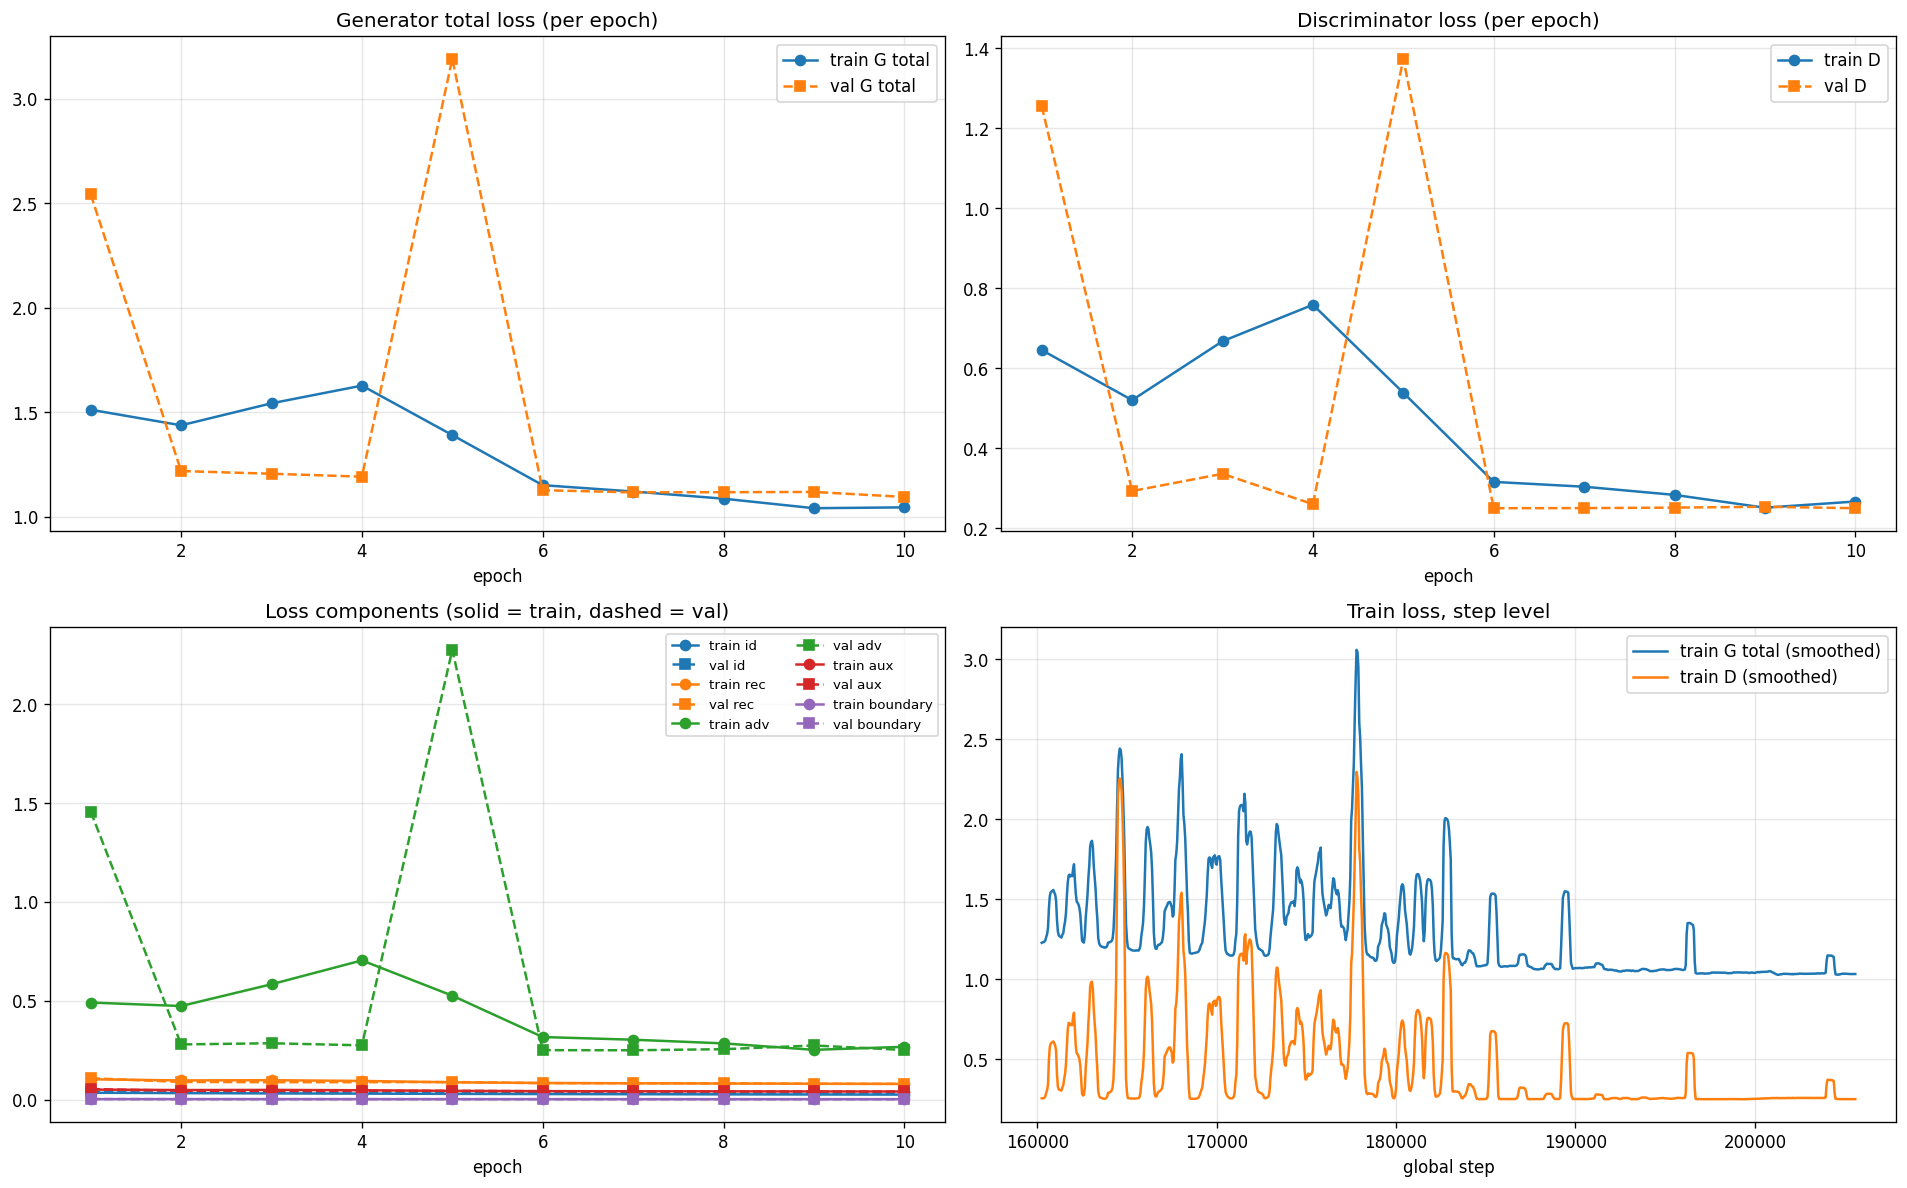

latest epoch visual: /kaggle/working/visual/epoch_010_overview.png


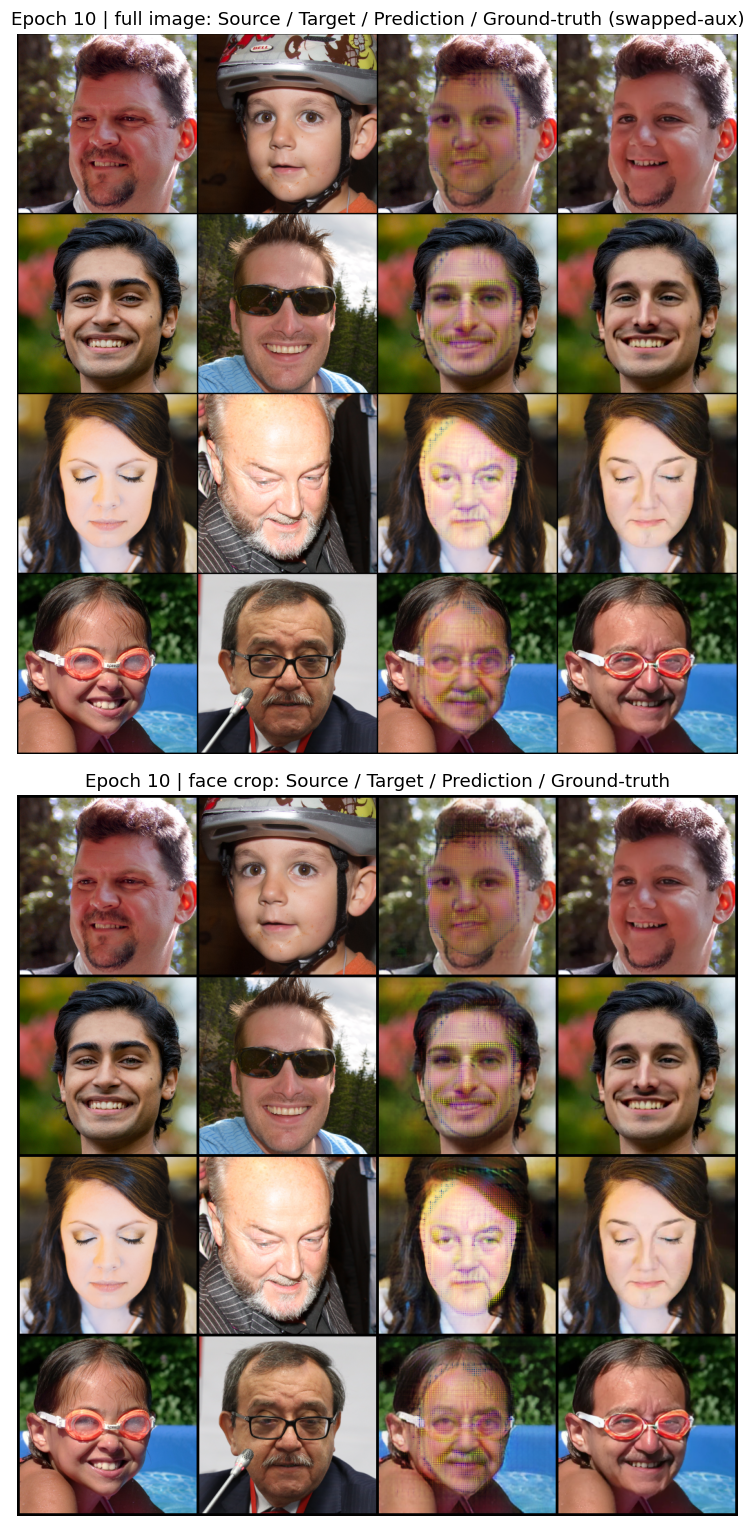

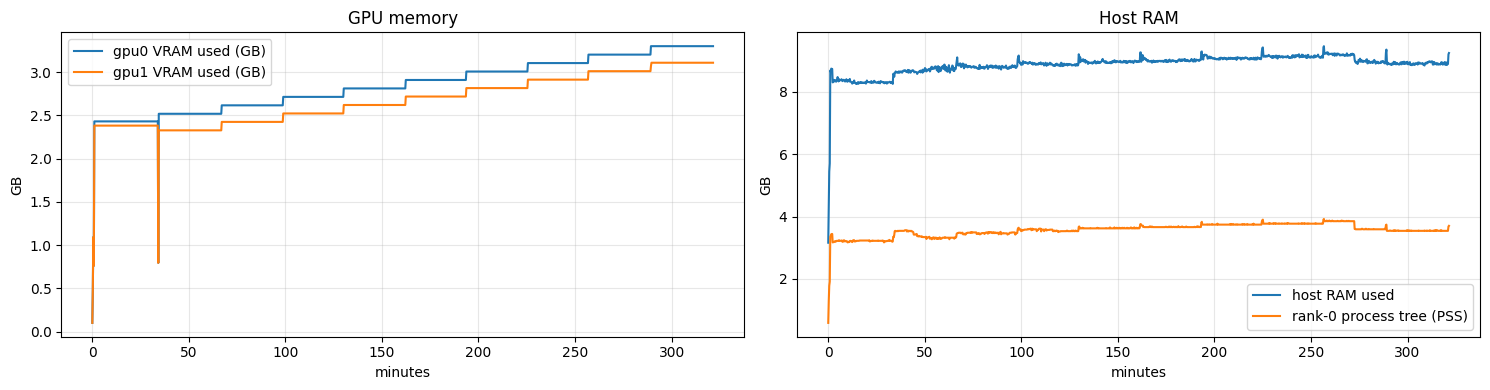


Saved under /kaggle/working/visual
   epoch_001
   epoch_001_overview.png
   epoch_002
   epoch_002_overview.png
   epoch_003
   epoch_003_overview.png
   epoch_004
   epoch_004_overview.png
   epoch_005
   epoch_005_overview.png
   epoch_006
   epoch_006_overview.png
   epoch_007
   epoch_007_overview.png
   epoch_008
   epoch_008_overview.png
   epoch_009
   epoch_009_overview.png
   epoch_010
   epoch_010_overview.png
   loss_curves.png
   loss_history.csv
   resource_log.csv
   resource_usage.png
   run_summary.json
   train_steps.csv


In [13]:
# ============================================================
# CELL 13 - show results (everything is also saved under /kaggle/working/visual)
# ============================================================
import glob, os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

VIS = CONFIG["visual_dir"]

hist_csv = f"{VIS}/loss_history.csv"
if os.path.exists(hist_csv):
    display(pd.read_csv(hist_csv))
if os.path.exists(f"{VIS}/run_summary.json"):
    print(open(f"{VIS}/run_summary.json").read())

if os.path.exists(f"{VIS}/loss_curves.png"):
    display(Image(f"{VIS}/loss_curves.png"))

overviews = sorted(glob.glob(f"{VIS}/epoch_*_overview.png"))
if overviews:
    print("latest epoch visual:", overviews[-1])
    display(Image(overviews[-1]))

# resource usage over time (VRAM of every GPU + host RAM)
res_csv = f"{VIS}/resource_log.csv"
if os.path.exists(res_csv):
    r = pd.read_csv(res_csv)
    t = r["t_s"] / 60.0
    fig, ax = plt.subplots(1, 2, figsize=(15, 4))
    for c in [c for c in r.columns if c.endswith("_used_mb")]:
        ax[0].plot(t, r[c] / 1024.0, label=c.replace("_used_mb", " VRAM used (GB)"))
    ax[0].set_xlabel("minutes"); ax[0].set_ylabel("GB"); ax[0].set_title("GPU memory"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(t, r["ram_used_gb"], label="host RAM used")
    ax[1].plot(t, r["rank0_procs_pss_gb"], label="rank-0 process tree (PSS)")
    ax[1].set_xlabel("minutes"); ax[1].set_ylabel("GB"); ax[1].set_title("Host RAM"); ax[1].legend(); ax[1].grid(alpha=.3)
    fig.tight_layout()
    fig.savefig(f"{VIS}/resource_usage.png", dpi=110)
    plt.show()

print("\nSaved under", VIS)
for p in sorted(glob.glob(f"{VIS}/*"))[:40]:
    print("  ", os.path.basename(p))
